# 06 - Validation

Evaluates every model (default and tuned) on the held-out test set and compares them.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

sns.set(style="darkgrid")

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

In [2]:
X_test = pd.read_csv('data/processed/X_test.csv')
y_test = pd.read_csv('data/processed/y_test.csv')['spend_next_month']
scaler = joblib.load('models/scaler.pkl')
X_test_sc = scaler.transform(X_test)

### Test Set Results

In [3]:
# model name: (file, needs scaling?)
models = {
    'Linear Regression':      ('linear_regression.pkl', True),
    'Random Forest':          ('random_forest.pkl', False),
    'XGBoost':                ('xgboost.pkl', False),
    'ANN':                    ('ann.pkl', True),
    'Random Forest (Optuna)': ('random_forest_optuna.pkl', False),
    'XGBoost (Optuna)':       ('xgboost_optuna.pkl', False),
    'ANN (Optuna)':           ('ann_optuna.pkl', True),
}

results = []
for name, (file, scaled) in models.items():
    model = joblib.load(f'models/{file}')
    pred = model.predict(X_test_sc if scaled else X_test)
    results.append([name,
                    mean_absolute_error(y_test, pred),
                    np.sqrt(mean_squared_error(y_test, pred)),
                    r2_score(y_test, pred)])

results_df = pd.DataFrame(results, columns=['Model', 'MAE', 'RMSE', 'R2']).sort_values('MAE').reset_index(drop=True)
results_df

,Model,MAE,RMSE,R2
0,XGBoost (Optuna),98.478650,147.619265,0.772280
1,Random Forest (Optuna),99.991598,149.049339,0.767847
2,Random Forest,100.794392,150.047624,0.764727
3,ANN (Optuna),102.697817,151.934265,0.758773
4,ANN,103.204669,154.799451,0.749589
5,XGBoost,105.160972,157.464336,0.740893
6,Linear Regression,109.808155,162.124424,0.725330


### Model Comparison

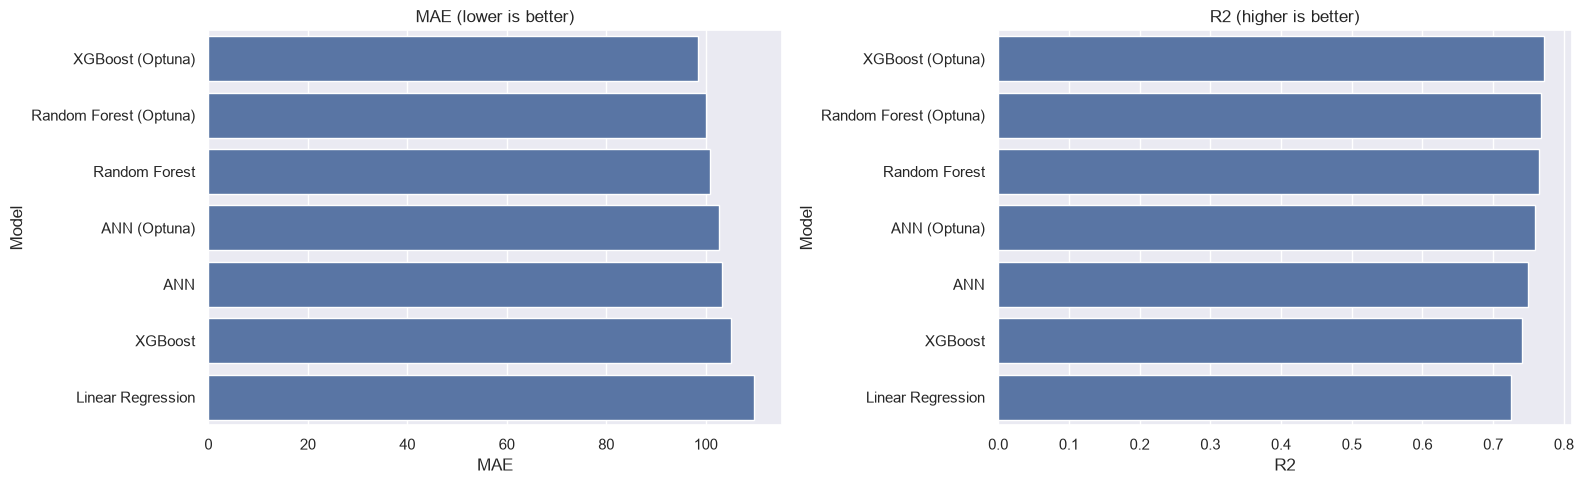

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16,5))
sns.barplot(data=results_df, y='Model', x='MAE', ax=axes[0])
axes[0].set_title('MAE (lower is better)')
sns.barplot(data=results_df, y='Model', x='R2', ax=axes[1])
axes[1].set_title('R2 (higher is better)')
plt.tight_layout()
plt.show()

### Actual vs Predicted (Best XGBoost)

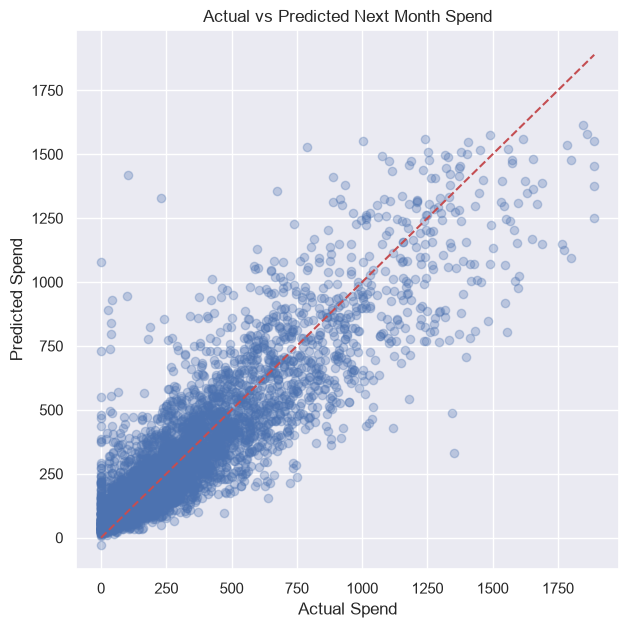

In [5]:
xgb_best = joblib.load('models/xgboost_optuna.pkl')
pred = xgb_best.predict(X_test)
plt.figure(figsize=(7,7))
plt.scatter(y_test, pred, alpha=0.3)
plt.plot([0, y_test.max()], [0, y_test.max()], 'r--')
plt.xlabel('Actual Spend')
plt.ylabel('Predicted Spend')
plt.title('Actual vs Predicted Next Month Spend')
plt.show()

### Residuals (Prediction Errors)

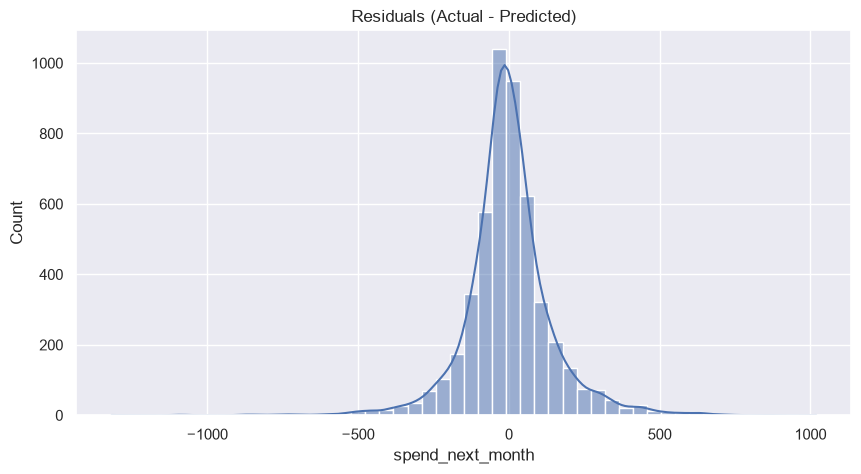

In [6]:
plt.figure(figsize=(10,5))
sns.histplot(y_test - pred, bins=50, kde=True)
plt.title('Residuals (Actual - Predicted)')
plt.show()

### Feature Importance (Best XGBoost)

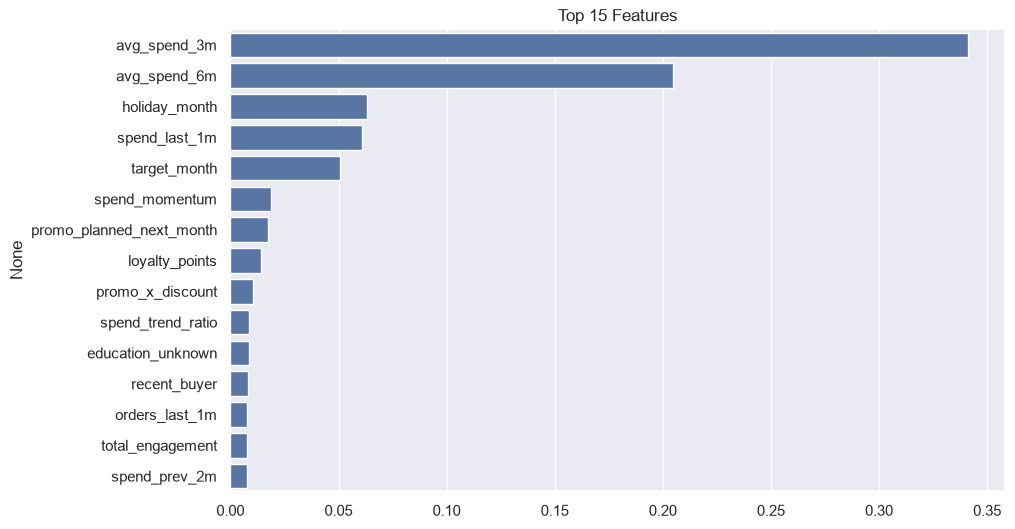

In [7]:
imp = pd.Series(xgb_best.feature_importances_, index=X_test.columns).sort_values(ascending=False).head(15)
plt.figure(figsize=(10,6))
sns.barplot(x=imp.values, y=imp.index)
plt.title('Top 15 Features')
plt.show()

**Conclusion**

- Preprocessing dropped the top 1% of spenders (above ~1,889), so these results apply to customers up to the 99th percentile of spend.
- EDA showed that past spend, recency, holiday months, membership tier and promos drive next month spend.
- Feature engineering added 8 new features, dropped redundant columns (`avg_order_value_6m` and three duplicates from preprocessing) and a sensitive one with no signal (`gender`), and used ordinal encoding for tier and education.
- All three main models (Random Forest, XGBoost, ANN) beat the Linear Regression baseline.
- Tuned XGBoost comes out on top: predictions are off by about 98 on average (MAE) and it explains about 77% of the variation in spend (R2).
- Optuna helped every model, XGBoost the most (MAE 105.2 → 98.5).
- The feature importance chart shows what drives next month spend most.